# 02 — Decision Tree
### Telco Customer Churn Prediction

A single Decision Tree is the most transparent non-linear model: its predictions are a short list of if-then rules.

**Shared protocol** (identical in notebooks 01–06):
- Same training set (3,944 customers) and same 5 stratified folds (`random_state = 34`).
- Same preprocessing (`FINAL_PREP_CONFIG` from notebook 00): binary add-ons, one-hot `InternetService` and `Contract`, binary `Dependents`/`PaperlessBilling`, standardised `log(1 + tenure)` and `MonthlyCharges`.
- Same tuning procedure: **nested cross-validation** (inner 5-fold grid search, outer 5-fold evaluation), scored by PR-AUC.
- Unweighted classes; class imbalance is handled at the decision threshold (notebook 08) and examined in notebook 07.
- The test set is **not used**. The nested out-of-fold predictions saved at the end are used for comparison and threshold selection in notebook 08.

## 1. How the Algorithm Works

A Decision Tree recursively splits the training data on the feature and threshold that most reduce **impurity** in the resulting groups:
- Gini impurity: $1-\sum_k p_k^2$;
- entropy: $-\sum_k p_k\log p_k$.

Each customer follows the splits down to a **leaf**, and the prediction is the churn share among the training customers in that leaf. Without limits, the tree keeps splitting until each leaf is pure, which memorises the training data.

## 2. Relevance, Assumptions and Limitations

- **Relevance:** captures non-linear effects and interactions (such as contract × internet service) automatically, and produces rules the CS team can read.
- **Assumptions:** none about the functional form.
- **Limitations:**
  - high variance: small changes in the data can change the whole tree;
  - predictions are coarse step functions, one probability per leaf;
  - an unconstrained tree overfits severely.

## 3. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's shared src/ package importable, wherever Jupyter was started
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data_preprocessing.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.tree import DecisionTreeClassifier, plot_tree
from src.data_preprocessing import FINAL_PREP_CONFIG, RANDOM_STATE, build_pipeline, load_raw_data, split_train_test
from src.evaluation import (cv_scores, final_search, fold_metrics, mean_std_table, nested_summary_row, run_nested_cv,
                            save_results, summarise_cv)
from src.visualization import plot_confusion, plot_permutation_importance, plot_reliability, save_figure, set_style

set_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

df = load_raw_data()                                       # validated raw data (read-only)
X_train, X_test, y_train, y_test = split_train_test(df)   # the project's single stratified 80/20 split
del X_test, y_test                                        # the test set is not used in this notebook
print(f"Training set: {X_train.shape[0]:,} customers, {int(y_train.sum()):,} churners ({y_train.mean():.2%})")
print("Preprocessing configuration (from notebook 00):", FINAL_PREP_CONFIG)

Training set: 3,944 customers, 1,053 churners (26.70%)
Preprocessing configuration (from notebook 00): {'contract': 'onehot', 'addons': 'binary', 'tenure': 'log'}


In [2]:
MODEL_NAME = "Decision Tree"
SLUG = "02_decision_tree"
INTERPRETABILITY_RANK = 2  # 1 = most interpretable

## 4. Preprocessing Pipeline

The shared pipeline is used unchanged so that all models see identical inputs. **Scaling and the log transform have no effect on a tree:** splits depend only on the order of values, and any monotone transformation preserves that order. One-hot columns let the tree split on individual categories.

In [3]:
ESTIMATOR = DecisionTreeClassifier(random_state=RANDOM_STATE)


pipeline = build_pipeline(ESTIMATOR, **FINAL_PREP_CONFIG)
print("Pipeline steps:", [name for name, _ in pipeline.steps])
print("Transformers:", [(name, cols) for name, _, cols in pipeline.named_steps["preprocess"].transformers])
print("Model:", ESTIMATOR)

Pipeline steps: ['preprocess', 'model']
Transformers: [('binary', ['Dependents', 'PaperlessBilling']), ('addons', ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']), ('internet', ['InternetService']), ('contract', ['Contract']), ('tenure_log', ['tenure']), ('numeric', ['MonthlyCharges'])]
Model: DecisionTreeClassifier(random_state=34)


## 5. Baseline Configuration

The baseline is an **unconstrained** tree (`max_depth=None`, `min_samples_leaf=1`), scikit-learn's default.

In [4]:
BASELINE_ESTIMATOR = DecisionTreeClassifier(random_state=RANDOM_STATE)


baseline_raw = cv_scores(build_pipeline(BASELINE_ESTIMATOR, **FINAL_PREP_CONFIG), X_train, y_train)
baseline = summarise_cv(baseline_raw)
display(mean_std_table(pd.DataFrame([baseline], index=["Baseline (5-fold CV, threshold 0.5)"])))
gap = {m: baseline[f"{m} train"] - baseline[f"{m} mean"] for m in ["F1", "ROC-AUC", "PR-AUC"]}
print("Train - validation gap:", {k: round(v, 3) for k, v in gap.items()})

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
"Baseline (5-fold CV, threshold 0.5)",0.728 ± 0.014,0.491 ± 0.025,0.486 ± 0.014,0.489 ± 0.017,0.655 ± 0.010,0.379 ± 0.013


Train - validation gap: {'F1': np.float64(0.499), 'ROC-AUC': np.float64(0.345), 'PR-AUC': np.float64(0.621)}


**Interpretation.**
- The unconstrained default tree **overfits severely**: training-fold PR-AUC exceeds validation PR-AUC by **0.62**, and validation ROC-AUC is only 0.655.
- Grown until its leaves are pure, the tree memorises individual training customers. Each leaf then predicts 0 or 1, so the probabilities are useless for ranking.
- This is a property of the *default settings*, not of decision trees in general.

## 6. Hyperparameter Tuning Methodology


Hyperparameters are tuned with **nested cross-validation**:
- the 5 outer folds hold out 20% of the training set in turn;
- on the other 80%, a full grid search with its own inner 5-fold CV chooses the configuration;
- the chosen configuration, refitted on that 80%, predicts the held-out outer fold.

The outer-fold labels never influence tuning, so the resulting out-of-fold (OOF) probabilities are honest estimates of how the *whole hyperparameter-tuning procedure* performs on unseen customers. (The preprocessing configuration was fixed beforehand in notebook 00 using the same training folds; notebook 08, Section 6 shows that re-selecting it inside the nested loop changes the estimate only marginally.) A simpler "tune on everything, then cross-validate" design would reuse the same labels for selection and evaluation, which makes the estimates optimistic.

| Hyperparameter | Values | Role |
|---|---|---|
| `max_depth` | 3, 4, 5, 6, 8, None | Maximum number of successive splits |
| `min_samples_leaf` | 1, 10, 25, 50, 100, 150 | Minimum customers per leaf; this also limits splitting, so `min_samples_split` is left at its default to avoid a redundant dimension |
| `criterion` | gini, entropy | Impurity measure |

In [5]:
PARAM_GRID = {"model__max_depth": [3, 4, 5, 6, 8, None], "model__min_samples_leaf": [1, 10, 25, 50, 100, 150], "model__criterion": ["gini", "entropy"]}


n_configurations = int(np.prod([len(v) for v in PARAM_GRID.values()]))
print(f"{n_configurations} configurations x 5 inner folds x 5 outer folds = {n_configurations * 25} fits "
      f"(+ {5} refits) in the nested CV")

72 configurations x 5 inner folds x 5 outer folds = 1800 fits (+ 5 refits) in the nested CV


## 7. Nested Cross-Validation Results

In [6]:
nested = run_nested_cv(ESTIMATOR, PARAM_GRID, X_train, y_train, FINAL_PREP_CONFIG, compute_importance=True)
print(f"Nested CV wall time: {nested['seconds']:.1f} s\n")
display(nested["folds"].round(4))
print("Mean ± std over the 5 outer folds (accuracy, precision, recall and F1 at the reference threshold 0.5):")
display(pd.DataFrame([nested_summary_row(nested)], index=[MODEL_NAME]))
print("Hyperparameters chosen by the inner search in each outer fold:")
for fold, params in enumerate(nested["params"], start=1):
    print(f"  fold {fold}: {params}")

Nested CV wall time: 8.3 s



,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,log_loss
fold,,,,,,,,
1,0.7744,0.5838,0.5450,0.5637,0.8325,0.6037,0.1441,0.4283
2,0.7985,0.6711,0.4834,0.5620,0.8357,0.6360,0.1386,0.5438
3,0.7896,0.6178,0.5592,0.5871,0.8152,0.6205,0.1466,0.6947
4,0.7909,0.6415,0.4857,0.5528,0.8240,0.6199,0.1426,0.5640
5,0.7995,0.6806,0.4667,0.5537,0.8402,0.6329,0.1381,0.4181


Mean ± std over the 5 outer folds (accuracy, precision, recall and F1 at the reference threshold 0.5):


,PR-AUC,ROC-AUC,Brier score,Accuracy,Precision,Recall,F1
Decision Tree,0.623 ± 0.011,0.830 ± 0.009,0.142 ± 0.003,0.791 ± 0.009,0.639 ± 0.035,0.508 ± 0.037,0.564 ± 0.012


Hyperparameters chosen by the inner search in each outer fold:
  fold 1: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 50}
  fold 2: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 50}
  fold 3: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 50}
  fold 4: {'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 50}
  fold 5: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 50}


**Interpretation.**
- Tuning transforms the tree: nested **PR-AUC 0.623 ± 0.011** and **ROC-AUC 0.830 ± 0.009**, up from 0.379 and 0.655.
- The inner search chooses **`min_samples_leaf = 50` in all five outer folds**, and usually unlimited depth. **Leaf size, not depth, is what controls overfitting here:** requiring at least 50 customers per leaf turns each leaf into a stable churn-rate estimate.
- The tuned tree is still the weakest of the tuned models. It is below Logistic Regression in every outer fold (notebook 08).

## 8. Final Hyperparameters

The same grid search is run once on the full training set. Its refitted pipeline is this algorithm's final candidate, which notebook 09 evaluates if it is selected. Comparing the best search score with the nested estimate shows the optimism of a non-nested search.

In [7]:
search = final_search(ESTIMATOR, PARAM_GRID, X_train, y_train, FINAL_PREP_CONFIG)
final_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
final_summary = pd.Series({
    "best hyperparameters": final_params,
    "search CV PR-AUC (best of grid)": round(search.best_score_, 4),
    "nested CV PR-AUC": round(nested["folds"]["pr_auc"].mean(), 4),
    "optimism of the search score": round(search.best_score_ - nested["folds"]["pr_auc"].mean(), 4),
    "train-fold PR-AUC of best configuration": round(search.cv_results_["mean_train_score"][search.best_index_], 4),
})
display(final_summary.to_frame("value"))

,value
best hyperparameters,"{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 50}"
search CV PR-AUC (best of grid),0.6265
nested CV PR-AUC,0.6226
optimism of the search score,0.0039
train-fold PR-AUC of best configuration,0.6792


## 9. Diagnostics (Nested Out-of-Fold Predictions)

The confusion matrix uses the reference threshold of 0.5 only; the operating threshold is chosen in notebook 08. The reliability diagram checks whether predicted probabilities match observed churn rates (**calibration**), and the precision-recall curve shows the ranking quality across all thresholds (**discrimination**).

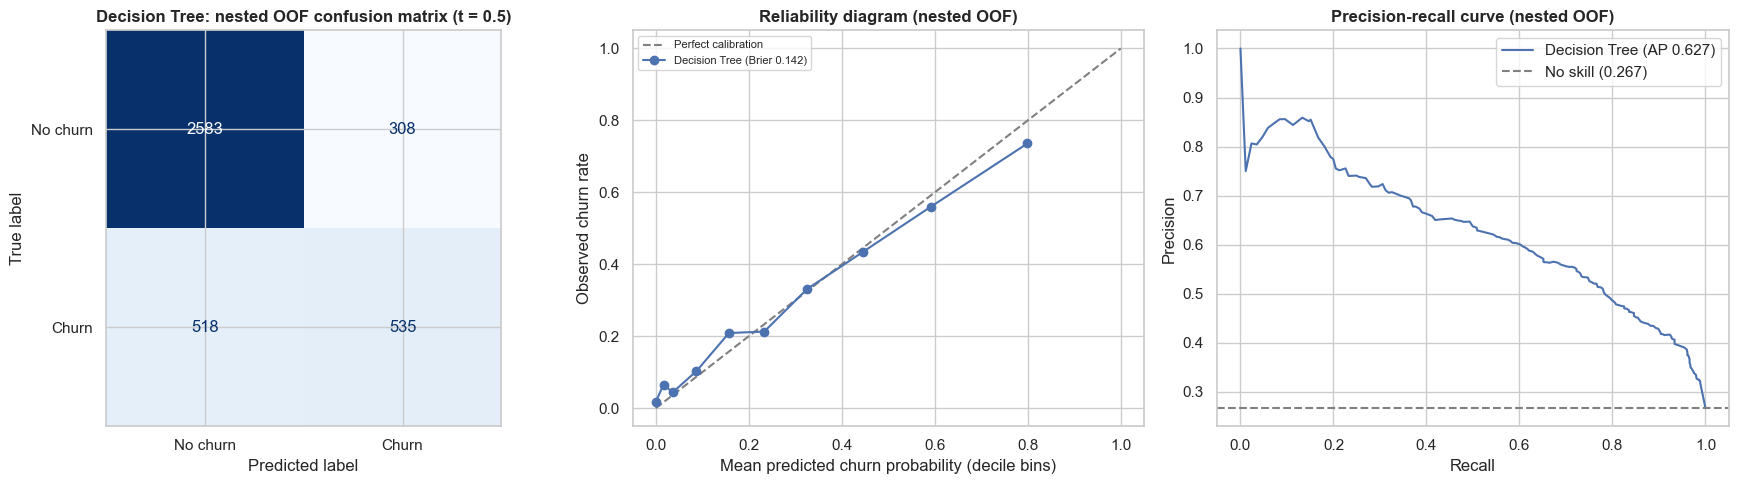

In [8]:
oof = nested["oof"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_confusion(axes[0], y_train, (oof >= 0.5).astype(int), f"{MODEL_NAME}: nested OOF confusion matrix (t = 0.5)")
plot_reliability(axes[1], y_train, {MODEL_NAME: oof}, "Reliability diagram (nested OOF)")
prec, rec, _ = precision_recall_curve(y_train, oof)
axes[2].plot(rec, prec, label=f"{MODEL_NAME} (AP {average_precision_score(y_train, oof):.3f})")
axes[2].axhline(y_train.mean(), linestyle="--", color="gray", label=f"No skill ({y_train.mean():.3f})")
axes[2].set_title("Precision-recall curve (nested OOF)")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
plt.tight_layout()
save_figure(fig, f"{SLUG}_diagnostics")
plt.show()

**Interpretation.**
- **At t = 0.5:** 535 of 1,053 churners are caught, 518 missed, and 308 non-churners flagged.
- **Calibration** is reasonable (Brier 0.142) but uneven. The curve has steps because the tree outputs only one probability per leaf (54 leaves), so many customers share identical scores.
- That coarseness also lowers the **precision-recall curve** (pooled AP 0.627), compared with the smoother models.

## 10. Model Interpretation

The top levels of the final tree show the main rules. Numeric thresholds refer to standardised values: `tenure_log` is on the log scale and `MonthlyCharges` in SD units.

**Permutation importance** is the drop in PR-AUC when one original feature's values are shuffled. It is computed inside the nested CV, on each outer validation fold, for the model tuned and fitted without that fold, so it inherits no selection leakage. Shuffling one of two features that share information understates both. Importance describes what the *model* relies on; it is not a causal effect.

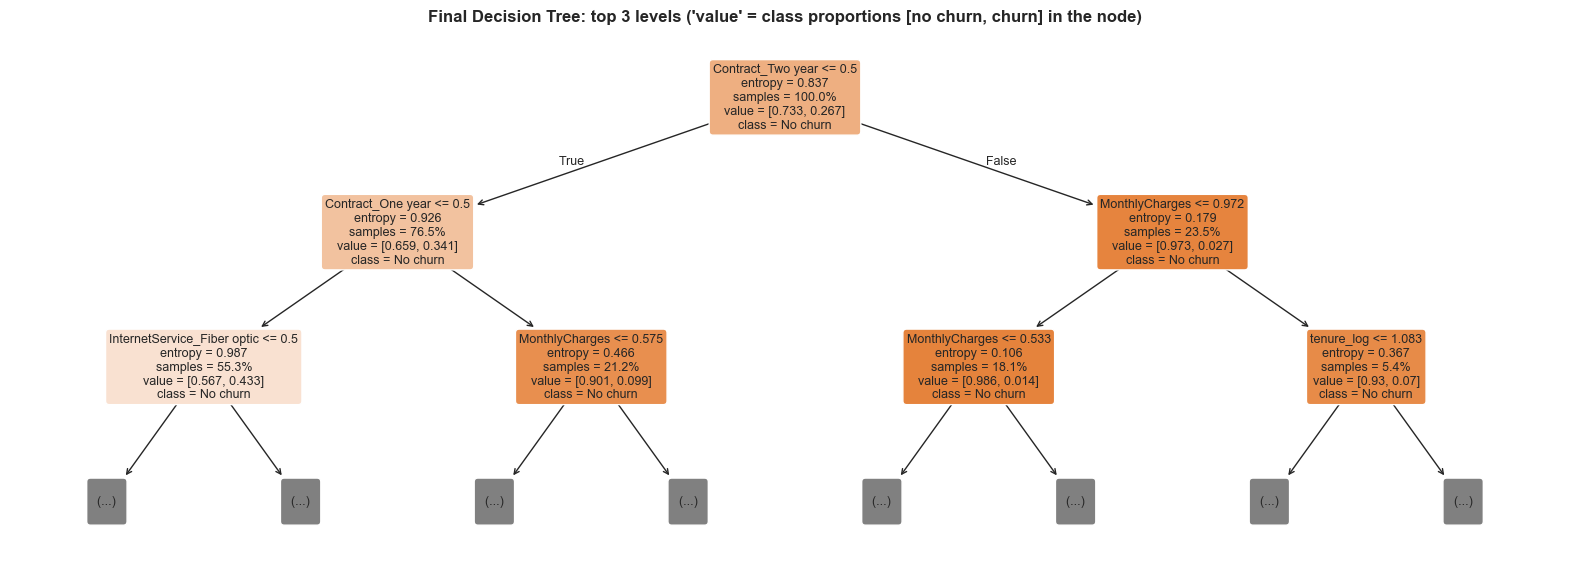

Depth of the final tree: 10 | leaves: 54


In [9]:
final_pipeline = search.best_estimator_
fig, ax = plt.subplots(figsize=(20, 7))
plot_tree(final_pipeline.named_steps["model"], feature_names=final_pipeline.named_steps["preprocess"].get_feature_names_out(),
          class_names=["No churn", "Churn"], max_depth=2, filled=True, proportion=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Final Decision Tree: top 3 levels ('value' = class proportions [no churn, churn] in the node)")
save_figure(fig, f"{SLUG}_tree")
plt.show()
print(f"Depth of the final tree: {final_pipeline.named_steps['model'].get_depth()} | "
      f"leaves: {final_pipeline.named_steps['model'].get_n_leaves()}")

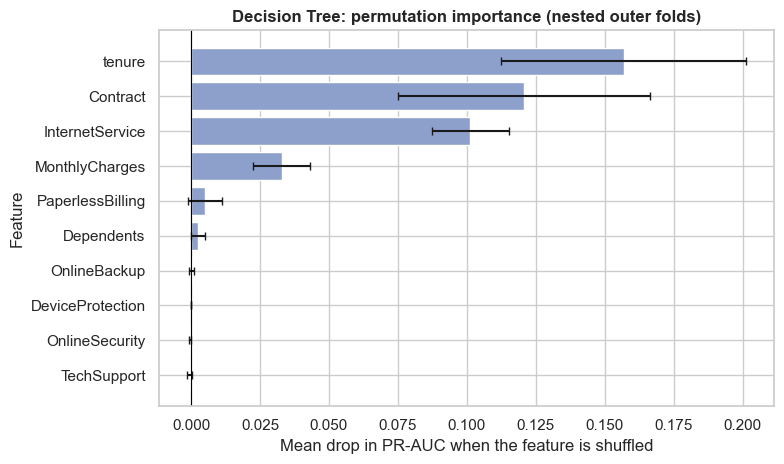

,mean,std
feature,,
tenure,0.1568,0.0444
Contract,0.1207,0.0458
InternetService,0.1012,0.0140
MonthlyCharges,0.0328,0.0103
PaperlessBilling,0.0050,0.0061
Dependents,0.0024,0.0025
OnlineBackup,0.0002,0.0008
DeviceProtection,0.0000,0.0000
OnlineSecurity,-0.0003,0.0004


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.8))
perm_summary = plot_permutation_importance(ax, nested["importance"],
                                           f"{MODEL_NAME}: permutation importance (nested outer folds)")
plt.tight_layout()
save_figure(fig, f"{SLUG}_permutation_importance")
plt.show()
display(perm_summary.sort_values("mean", ascending=False).round(4))

**Interpretation.**
- **The first two splits are both on Contract** (two-year, then one-year). The next level splits on **fiber-optic internet** and **monthly charges** for month-to-month customers, and on **tenure** for long-contract customers.
- These are readable rules that match the EDA. For example, month-to-month fiber customers form the high-risk branch.
- The full tree is 10 levels deep with 54 leaves, so only its top levels are practical to communicate.
- **Permutation importance** concentrates almost entirely on `tenure` (0.157), `Contract` (0.121) and `InternetService` (0.101). The add-ons contribute nothing, because the tree rarely reaches splits on them.

## 11. Strengths, Weaknesses and Conclusion

**Strengths**
- Transparent rules.
- Captures interactions without any feature engineering.
- Leaf-size regularisation is easy to explain.

**Weaknesses**
- The weakest ranking among the tuned models (nested PR-AUC 0.623).
- Coarse, step-shaped probabilities.
- Unstable structure: a small data change can alter the tree.

**Conclusion:** the Decision Tree is useful for explaining the main churn segments, but it is not competitive as a scoring model. Notebook 03 tests whether averaging many trees removes its weaknesses.

### Saving the training-stage results

The nested OOF predictions, fold metrics, permutation importances and the final (training-set) pipeline are stored in `reports/cv_results/` for the comparison in notebook 08.

In [11]:
payload = {
    "name": MODEL_NAME, "slug": SLUG, "oof": nested["oof"], "folds": nested["folds"], "params": nested["params"],
    "importance": nested["importance"], "seconds": nested["seconds"], "baseline": baseline,
    "final_params": final_params, "final_search_score": search.best_score_,
    "final_train_score": search.cv_results_["mean_train_score"][search.best_index_],
    "final_pipeline": search.best_estimator_, "grid": PARAM_GRID, "prep_config": FINAL_PREP_CONFIG,
    "y_index": y_train.index.to_numpy(), "interpretability_rank": INTERPRETABILITY_RANK,
}
print("Saved:", save_results(SLUG, payload).relative_to(PROJECT_ROOT))

Saved: reports\cv_results\02_decision_tree.joblib
